# Does the baseline window mediate PRIME's predictions?

Two questions, on the online numbers in `trials_intervention.csv` and the stored
`*_baseline.npy` arrays — no replay, no recordings.

1. **Does PRIME's online `prediction_probability` relate to the online TEP label
   `tep_amplitude` (0–1)?**
2. **If it does, is that relationship carried by the pre-stimulus baseline window?**

Variables:

| | column / file | what it is |
|---|---|---|
| X | `prediction_probability` | the probability at the moment threshold was crossed (or, for `predetermined_single`, the retrospective prediction) |
| M | `<stem>_baseline.npy` row 0 | the per-channel offsets `apply_baseline` removed over −25…−15 ms, i.e. the baseline window itself |
| Y | `tep_amplitude` | the online CDF-normalised dipole label, 0–1 |

`tep_amplitude` is `NaN` for every `prime_triplet` trial, so the analysis set is the
single-pulse conditions only. Row 1 of `*_baseline.npy` (the post-ICA baseline) is
checked below and dropped — it carries no trial-to-trial information.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

LOOP_ROOT = Path(r"D:\Linus\Loop")
SESSIONS = {"pilot003": ("sub-pilot003", "103"),
            "pilot004": ("sub-pilot004", "104"),
            "pilot005": ("sub-pilot005", "105")}
N_BOOT = 5000
RNG = np.random.default_rng(0)

## 1. Load — trials + stored baselines

In [2]:
def load_session(subject, run):
    """Intervention trials of one session, with the stored baseline reduced to scalars."""
    d = LOOP_ROOT / "BIDS" / subject / "ses-prime" / run / "prime"
    df = pd.read_csv(d / "trials_intervention.csv")
    df = df[df.stage.str.startswith("intervention")].copy()
    df["stem"] = df.stage + "_" + df.trial_in_stage.map("{:04d}".format)

    b_mean, b_dev, b_post = [], [], []
    for stem in df.stem:
        f = d / f"{stem}_baseline.npy"
        if f.exists():
            b = np.load(f)               # (2, 60) -- row 0 pre-ICA, row 1 post-ICA
            b_mean.append(b[0].mean())   # global DC level in the baseline window
            b_dev.append(b[0].std())     # spatial spread (what survives the avg ref)
            b_post.append(b[1].std())
        else:
            b_mean.append(np.nan); b_dev.append(np.nan); b_post.append(np.nan)
    df["b_mean"], df["b_dev"], df["b_post"] = b_mean, b_dev, b_post
    return df


raw = {}
for name, (sub, run) in SESSIONS.items():
    df = load_session(sub, run)
    raw[name] = df
    print(f"{name}: {len(df)} intervention trials, "
          f"{df.b_mean.notna().sum()} with a stored baseline, "
          f"{df.prediction_probability.notna().sum()} with a prediction, "
          f"{df.tep_amplitude.notna().sum()} with a TEP label")

pilot003: 800 intervention trials, 800 with a stored baseline, 734 with a prediction, 273 with a TEP label
pilot004: 800 intervention trials, 800 with a stored baseline, 712 with a prediction, 290 with a TEP label
pilot005: 800 intervention trials, 800 with a stored baseline, 771 with a prediction, 295 with a TEP label


### Row 1 of `*_baseline.npy` is a constant

The post-ICA `apply_baseline` removes the same thing on every trial, to ~12 decimal
places. Only row 0 is usable as a mediator.

In [3]:
for name, df in raw.items():
    v = df.b_post.dropna()
    print(f"{name}: row-1 spread across trials = {v.std():.2e}   (value {v.mean():.3e})")

pilot003: row-1 spread across trials = 1.62e-13   (value 3.473e-03)
pilot004: row-1 spread across trials = 1.51e-13   (value 5.979e-03)
pilot005: row-1 spread across trials = 8.70e-14   (value 8.091e-03)


### Analysis set

Trials that have both a prediction and a TEP label. Everything is z-scored **within
session**, so the three sessions can be pooled without their different offsets and
scales leaking in.

In [4]:
def z(v):
    v = np.asarray(v, float)
    return (v - v.mean()) / v.std(ddof=1)


rows = []
for name, df in raw.items():
    d = df.dropna(subset=["prediction_probability", "tep_amplitude", "b_mean"]).copy()
    d["subject"] = name
    d["x"] = z(d.prediction_probability)   # X
    d["y"] = z(d.tep_amplitude)            # Y
    d["m_mean"] = z(d.b_mean)              # M  (baseline level)
    d["m_dev"] = z(d.b_dev)                # M' (baseline spatial spread)
    d["t"] = z(d.pulse_time)               # time within session
    rows.append(d)

D = pd.concat(rows, ignore_index=True)
print(D.groupby(["subject", "condition"]).size(), "\n\ntotal:", len(D))

subject   condition           
pilot003  predetermined_single     64
          prime_single_pulse      186
pilot004  predetermined_single     70
          prime_single_pulse      198
pilot005  predetermined_single     74
          prime_single_pulse      212
dtype: int64 

total: 804


## 2. Prediction vs TEP label

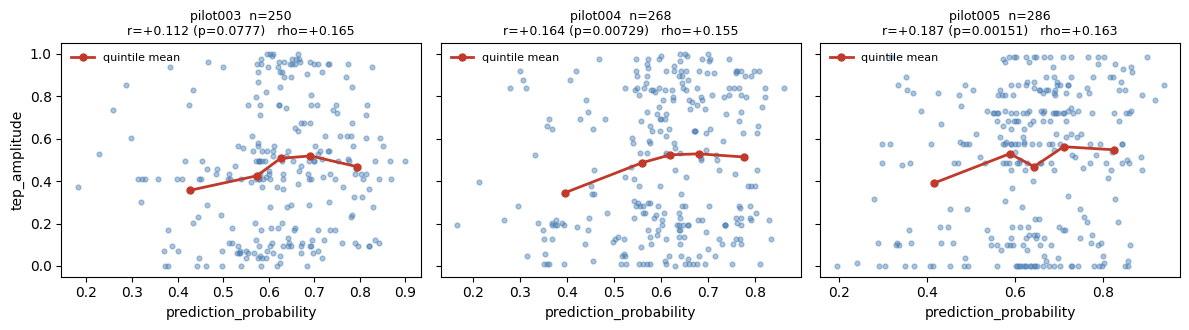

In [5]:
fig, axes = plt.subplots(1, len(raw), figsize=(4 * len(raw), 3.4), sharey=True)
for ax, (name, d) in zip(np.atleast_1d(axes), D.groupby("subject")):
    ax.scatter(d.prediction_probability, d.tep_amplitude, s=12, alpha=.45, color="#4a7fb5")
    q = pd.qcut(d.prediction_probability, 5, duplicates="drop")
    b = d.groupby(q, observed=True).agg(x=("prediction_probability", "mean"),
                                        y=("tep_amplitude", "mean"))
    ax.plot(b.x, b.y, "o-", color="#c0392b", lw=2, ms=5, label="quintile mean")
    r, p = stats.pearsonr(d.prediction_probability, d.tep_amplitude)
    rho, ps = stats.spearmanr(d.prediction_probability, d.tep_amplitude)
    ax.set_title(f"{name}  n={len(d)}\nr={r:+.3f} (p={p:.3g})   rho={rho:+.3f}", fontsize=9)
    ax.set_xlabel("prediction_probability")
    ax.legend(fontsize=8, frameon=False)
np.atleast_1d(axes)[0].set_ylabel("tep_amplitude")
fig.tight_layout()
plt.show()

In [6]:
print("pooled, within-session z-scores\n")
for a_, b_, lab in [("x", "y", "prediction -> TEP label      (c)"),
                    ("x", "m_mean", "prediction -> baseline       (a)"),
                    ("m_mean", "y", "baseline   -> TEP label      (b)"),
                    ("t", "m_mean", "time       -> baseline"),
                    ("t", "x", "time       -> prediction"),
                    ("t", "y", "time       -> TEP label")]:
    r, p = stats.pearsonr(D[a_], D[b_])
    print(f"{lab:34s} r={r:+.3f}   p={p:.3g}")

pooled, within-session z-scores

prediction -> TEP label      (c)   r=+0.156   p=9.17e-06
prediction -> baseline       (a)   r=-0.514   p=1.59e-55
baseline   -> TEP label      (b)   r=-0.048   p=0.176
time       -> baseline             r=+0.966   p=0
time       -> prediction           r=-0.509   p=4.27e-54
time       -> TEP label            r=-0.038   p=0.287


## 3. The baseline is mostly a clock

Before reading the `prediction -> baseline` correlation as a relationship, note what
the baseline level actually does over a session: it drifts, almost monotonically.
Any variable that also changes over the session will correlate with it for that
reason alone, so **time has to be a covariate** in everything below.

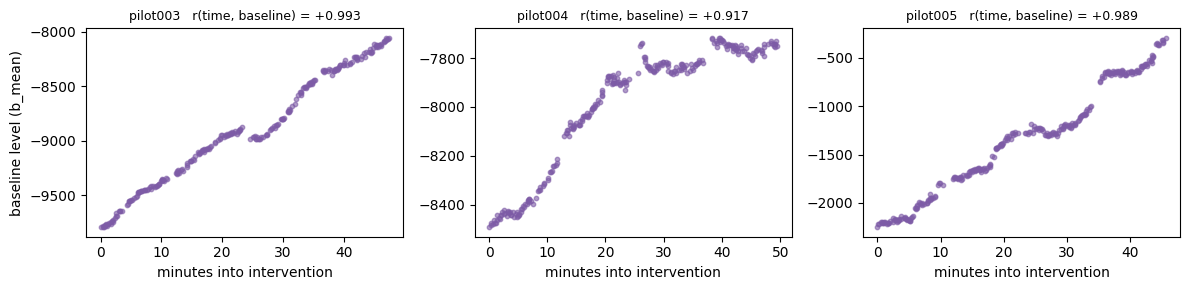

In [7]:
fig, axes = plt.subplots(1, len(raw), figsize=(4 * len(raw), 3), sharey=False)
for ax, (name, d) in zip(np.atleast_1d(axes), D.groupby("subject")):
    mins = (d.pulse_time - d.pulse_time.min()) / 60
    ax.scatter(mins, d.b_mean, s=10, alpha=.6, color="#7d5ba6")
    r, p = stats.pearsonr(d.pulse_time, d.b_mean)
    ax.set_title(f"{name}   r(time, baseline) = {r:+.3f}", fontsize=9)
    ax.set_xlabel("minutes into intervention")
np.atleast_1d(axes)[0].set_ylabel("baseline level (b_mean)")
fig.tight_layout()
plt.show()

## 4. Mediation

Standard three-path decomposition on the z-scored variables:

* **a** — baseline ~ prediction
* **b** — TEP ~ baseline, controlling for the prediction
* **c** — TEP ~ prediction (total)
* **c'** — TEP ~ prediction, controlling for the baseline (direct)
* **indirect** = a·b, with a percentile bootstrap CI over trials

Run twice: without a covariate, and with time. `m_mean` is the baseline level,
`m_dev` its spatial spread.

In [8]:
def ols(y, X):
    """X without intercept. Returns (betas, ses, ps) for [const, *cols]."""
    X = np.column_stack([np.ones(len(y)), X])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    dof = len(y) - X.shape[1]
    cov = (resid @ resid / dof) * np.linalg.pinv(X.T @ X)
    se = np.sqrt(np.diag(cov))
    return beta, se, 2 * stats.t.sf(np.abs(beta / se), dof)


def mediate(x, m, y, cov=None, n_boot=N_BOOT, rng=RNG):
    def paths(x, m, y, cov):
        Xa = np.column_stack([x] + ([cov] if cov is not None else []))
        a = ols(m, Xa)[0][1]                                  # M ~ X (+cov)
        c = ols(y, Xa)[0][1]                                  # Y ~ X (+cov)
        Xb = np.column_stack([x, m] + ([cov] if cov is not None else []))
        beta = ols(y, Xb)[0]                                  # Y ~ X + M (+cov)
        return a, beta[2], c, beta[1]                         # a, b, c, c'

    a, b, c, cp = paths(x, m, y, cov)
    n = len(x)
    ind = np.empty(n_boot)
    for i in range(n_boot):
        k = rng.integers(0, n, n)
        aa, bb, _, _ = paths(x[k], m[k], y[k], None if cov is None else cov[k])
        ind[i] = aa * bb
    lo, hi = np.percentile(ind, [2.5, 97.5])
    return dict(n=n, a=a, b=b, c=c, c_direct=cp, indirect=a * b, ci_lo=lo, ci_hi=hi)


out = []
for med in ["m_mean", "m_dev"]:
    for cov_name, cov in [("none", None), ("time", D[["t"]].to_numpy())]:
        res = mediate(D.x.to_numpy(), D[med].to_numpy(), D.y.to_numpy(), cov)
        out.append(dict(mediator=med, covariate=cov_name, **res))

pd.DataFrame(out).round(3)

,mediator,covariate,n,a,b,c,c_direct,indirect,ci_lo,ci_hi
0,m_mean,none,804,-0.514,0.044,0.156,0.178,-0.023,-0.065,0.018
1,m_mean,time,804,-0.031,-0.109,0.184,0.181,0.003,-0.005,0.014
2,m_dev,none,804,-0.476,0.037,0.156,0.173,-0.017,-0.056,0.019
3,m_dev,time,804,0.004,-0.097,0.184,0.185,-0.000,-0.006,0.004


### Per session, time-adjusted

In [9]:
out = []
for name, d in D.groupby("subject"):
    res = mediate(z(d.prediction_probability), z(d.b_mean), z(d.tep_amplitude),
                  z(d.pulse_time)[:, None], n_boot=2000)
    out.append(dict(subject=name, **res))

pd.DataFrame(out).round(3)

,subject,n,a,b,c,c_direct,indirect,ci_lo,ci_hi
0,pilot003,250,-0.008,-0.183,0.090,0.088,0.001,-0.009,0.017
1,pilot004,268,-0.075,-0.066,0.222,0.217,0.005,-0.023,0.032
2,pilot005,286,-0.003,-0.137,0.214,0.214,0.000,-0.008,0.012


## How to read the table

* **a collapses once time is a covariate.** The raw `prediction -> baseline`
  correlation is large, but the baseline level is ~0.95 correlated with time within a
  session, and so is the prediction (the threshold adapts and the model finetunes).
  Almost all of `a` is that shared drift, not a trial-by-trial link.
* **b is near zero either way.** The baseline window does not predict the TEP label
  once the prediction is in the model.
* So the **indirect path is null** — its CI straddles zero — and `c'` is
  indistinguishable from `c`. The prediction→TEP relationship is not going through
  the baseline window; if anything it is slightly *cleaner* after adjusting for time.

Caveats worth keeping in view:

* PRIME trials only fire when `p >= threshold`, so X is range-restricted on those
  trials; `predetermined_single` trials carry a *retrospective* prediction made under
  different conditions. Both are in the pooled set — split by `condition` to check.
* `b_mean` and `b_dev` are two summaries of one 60-channel vector, and they behave
  almost identically here. A different reduction (e.g. a single channel, or a
  projection onto the dipole orientation) could behave differently.
* This is the online label pipeline end to end. It says nothing about whether a
  *different* baseline window would change the label — that question lives in
  `pre_post_coupling.ipynb` section 9.